In [ ]:
!pip install -q transformers scikit-learn pillow imagehash requests google-genai gradio joblib matplotlib pandas

import os, json, glob, time, io, requests
import numpy as np
from PIL import Image

# Optional: save work to Google Drive so you don't lose it if Colab resets
from google.colab import drive
drive.mount('/content/drive')
os.makedirs('/content/drive/MyDrive/folkart', exist_ok=True)

ARTS = ["madhubani", "warli", "gond", "pattachitra"]
for a in ARTS:
    os.makedirs(f"data/{a}", exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
knowledge_base = {
  "madhubani": {
    "name": "Madhubani / Mithila painting",
    "origin": "Mithila region, Bihar (India) and Nepal. Traditionally painted by women on walls and floors, now on paper and cloth.",
    "features": [
      {"id": "double_border", "prompt": "a folk painting with a double line border and a floral border pattern",
       "description": "Paintings are framed with a double-line border, often decorated with flowers or geometric patterns.",
       "tip": "Draw two parallel lines around the painting and fill the band between them with a repeating pattern."},
      {"id": "fill_patterns", "prompt": "shapes filled with dots, hatching and cross-hatched line patterns",
       "description": "Figures and shapes are filled with fine hatching, cross-hatching, dots and small repeating motifs instead of shading.",
       "tip": "Replace any shading with line hatching, dots or tiny repeated patterns inside the shapes."},
      {"id": "no_empty_space", "prompt": "a densely filled painting with no empty background space, full of motifs",
       "description": "The composition is packed. Gaps between main figures are filled with flowers, leaves, birds or patterns.",
       "tip": "Look for blank areas and fill them with leaves, flowers, dots or small motifs."},
      {"id": "motifs", "prompt": "folk painting of fish, peacock, lotus flowers, sun and moon",
       "description": "Common motifs: fish, peacocks, lotus, sun, moon, trees and gods, each with symbolic meaning (fertility, prosperity, love).",
       "tip": "Include at least one traditional motif such as a fish, peacock or lotus."},
      {"id": "faces_eyes", "prompt": "faces drawn in profile with large almond shaped eyes and a pointed nose",
       "description": "Faces are in profile, with big almond-shaped eyes, a pointed nose and a stylized body.",
       "tip": "Draw faces side-on with large, elongated eyes, and avoid realistic proportions."},
      {"id": "flat_bold_color", "prompt": "flat bright colors red yellow green blue with bold black outlines, no shading",
       "description": "Flat, bright natural colors with strong black outlines and no realistic shading or perspective.",
       "tip": "Use flat color blocks outlined in black. No gradients, no 3D shading."}
    ]
  },
  "warli": {
    "name": "Warli painting",
    "origin": "Warli tribe, Maharashtra (Thane/Palghar region). Traditionally on mud-wall huts using rice paste.",
    "features": [
      {"id": "white_on_earth", "prompt": "white line drawing on a reddish brown earthy mud background",
       "description": "Classic Warli uses only white (rice paste) on a red-ochre or mud-brown background.",
       "tip": "Use a dark red-brown or earthy base and paint only in white. Avoid adding many colors."},
      {"id": "geometric_figures", "prompt": "tiny stick figures made of two triangles and a circle head",
       "description": "People are made from basic shapes: a circle for the head and two triangles joined at the tips for the body.",
       "tip": "Build humans from a circle and two triangles meeting at their points. Keep limbs as thin lines."},
      {"id": "circle_dance", "prompt": "many people dancing in a circle or spiral chain holding hands",
       "description": "The famous tarpa dance shows a spiral or circular chain of dancers around a central figure or instrument.",
       "tip": "Arrange figures in a circle or spiral, holding hands or touching."},
      {"id": "village_scenes", "prompt": "a flat village life scene with huts, trees, farming, no shading and no perspective",
       "description": "Scenes show everyday life: farming, hunting, festivals, huts and trees, drawn flat without perspective.",
       "tip": "Depict daily-life activities and keep everything flat. Avoid shadows and depth."},
      {"id": "geometric_frame", "prompt": "a rectangular frame with repeating geometric patterns and squares",
       "description": "Squares and rectangular frames with repeated geometric motifs are central to Warli ritual paintings.",
       "tip": "Frame the artwork with a square or rectangle and use repeating triangles and squares."}
    ]
  },
  "gond": {
    "name": "Gond painting",
    "origin": "Gond community, Madhya Pradesh (Patangarh, Dindori).",
    "features": [
      {"id": "dots_dashes", "prompt": "an animal body filled with patterns of dots, dashes and fine lines",
       "description": "Bodies of animals and birds are filled with intricate dots, dashes and line patterns.",
       "tip": "Fill the body shapes with rows of dots and short dashes instead of solid color."},
      {"id": "vivid_colors", "prompt": "vivid colorful flat folk painting of animals and birds",
       "description": "Bright, saturated colors, often on dark or colorful backgrounds, with flat color fields.",
       "tip": "Use bold saturated colors and keep them flat."},
      {"id": "tree_of_life", "prompt": "a large tree with birds and animals in folk art style",
       "description": "Nature is central: trees, animals and birds are sacred subjects, with the tree of life a popular motif.",
       "tip": "Make a tree, an animal or a bird the hero of the composition."},
      {"id": "flowing_lines", "prompt": "fine parallel flowing lines creating movement, without shading",
       "description": "Fine parallel lines follow the shape of the body and give a sense of movement without shading.",
       "tip": "Use groups of fine, parallel lines that follow the curves of the body."}
    ]
  },
  "pattachitra": {
    "name": "Pattachitra",
    "origin": "Odisha and West Bengal. Traditional cloth/palm-leaf scroll painting telling mythological stories.",
    "features": [
      {"id": "bold_outlines", "prompt": "bold black outlines with flat colors, traditional scroll painting",
       "description": "Strong, confident black outlines with flat color fills and no shading.",
       "tip": "Make your outlines bold and continuous, and fill with flat color."},
      {"id": "big_eyes", "prompt": "faces with large elongated eyes of mythological characters",
       "description": "Characters have large, elongated eyes and stylized, expressive faces.",
       "tip": "Draw long, wide eyes and keep faces stylized, never realistic."},
      {"id": "floral_border", "prompt": "a decorative floral border around a painting",
       "description": "A decorative border of flowers or vines frames the central scene.",
       "tip": "Add a continuous floral or vine border around the artwork."},
      {"id": "natural_palette", "prompt": "limited palette of red yellow white black and indigo",
       "description": "Natural pigments: a limited palette of red, yellow, white, black and indigo/blue.",
       "tip": "Restrict yourself to red, yellow, white, black and a touch of blue for an authentic look."},
      {"id": "mythology", "prompt": "a mythological scene of Hindu gods in a flat folk style",
       "description": "Stories from the Ramayana, Mahabharata and Krishna/Jagannath legends are the main subjects.",
       "tip": "Choose a mythological story and show its characters clearly."}
    ]
  }
}
json.dump(knowledge_base, open("knowledge_base.json", "w"), indent=2, ensure_ascii=False)

In [ ]:
API = "https://commons.wikimedia.org/w/api.php"
HEADERS = {"User-Agent": "FolkArtHackathon/0.1 (student project; your_email@example.com)"}

def search_commons(query, want=70):
    """Search Wikimedia Commons for image files and return urls + license info."""
    out, cont = [], {}
    while len(out) < want:
        params = {
            "action": "query", "format": "json", "generator": "search",
            "gsrsearch": query, "gsrnamespace": 6, "gsrlimit": 50,
            "prop": "imageinfo", "iiprop": "url|mime|extmetadata", "iiurlwidth": 800, **cont,
        }
        try:
            res = requests.get(API, params=params, headers=HEADERS, timeout=30)
            if res.status_code != 200:
                print(f"API request failed with status code {res.status_code}")
                break
            r = res.json()
        except Exception as e:
            print(f"Error fetching/parsing JSON for query '{query}': {e}")
            break

        pages = r.get("query", {}).get("pages", {})
        for p in pages.values():
            ii = p.get("imageinfo", [{}])[0]
            if ii.get("mime") not in ("image/jpeg", "image/png"):
                continue
            meta = ii.get("extmetadata", {})
            out.append({
                "title": p["title"],
                "url": ii.get("thumburl") or ii.get("url"),
                "license": meta.get("LicenseShortName", {}).get("value", ""),
                "author": meta.get("Artist", {}).get("value", ""),
            })
        if "continue" in r:
            cont = r["continue"]
        else:
            break
        time.sleep(1)
    return out[:want]

def download(items, folder):
    meta = []
    for i, it in enumerate(items):
        try:
            r = requests.get(it["url"], headers=HEADERS, timeout=30)
            if r.status_code != 200:
                continue
            path = f"{folder}/{i:03d}.jpg"
            with open(path, "wb") as f:
                f.write(r.content)
            meta.append({**it, "file": path})
            time.sleep(1)
        except Exception as e:
            print("skip", e)
    return meta

queries = {
    "madhubani":   ["Madhubani painting", "Mithila painting"],
    "warli":       ["Warli painting", "Warli art"],
    "gond":        ["Gond painting", "Gond art"],
    "pattachitra": ["Pattachitra", "Patachitra painting"],
}

all_meta = []
for art, qs in queries.items():
    items = []
    for q in qs:
        items += search_commons(q, want=40)
    seen, uniq = set(), []
    for it in items:                 # remove duplicate urls
        if it["url"] not in seen:
            seen.add(it["url"]); uniq.append(it)
    m = download(uniq[:90], f"data/{art}")
    all_meta += [{**x, "art": art} for x in m]
    print(art, len(m), "downloaded")

# Keep a record for attribution (important for credit and ethics)
import pandas as pd
pd.DataFrame(all_meta).to_csv("image_credits.csv", index=False)

madhubani 46 downloaded
warli 52 downloaded
gond 44 downloaded
pattachitra 37 downloaded


madhubani 45 kept
warli 52 kept
gond 44 kept
pattachitra 37 kept


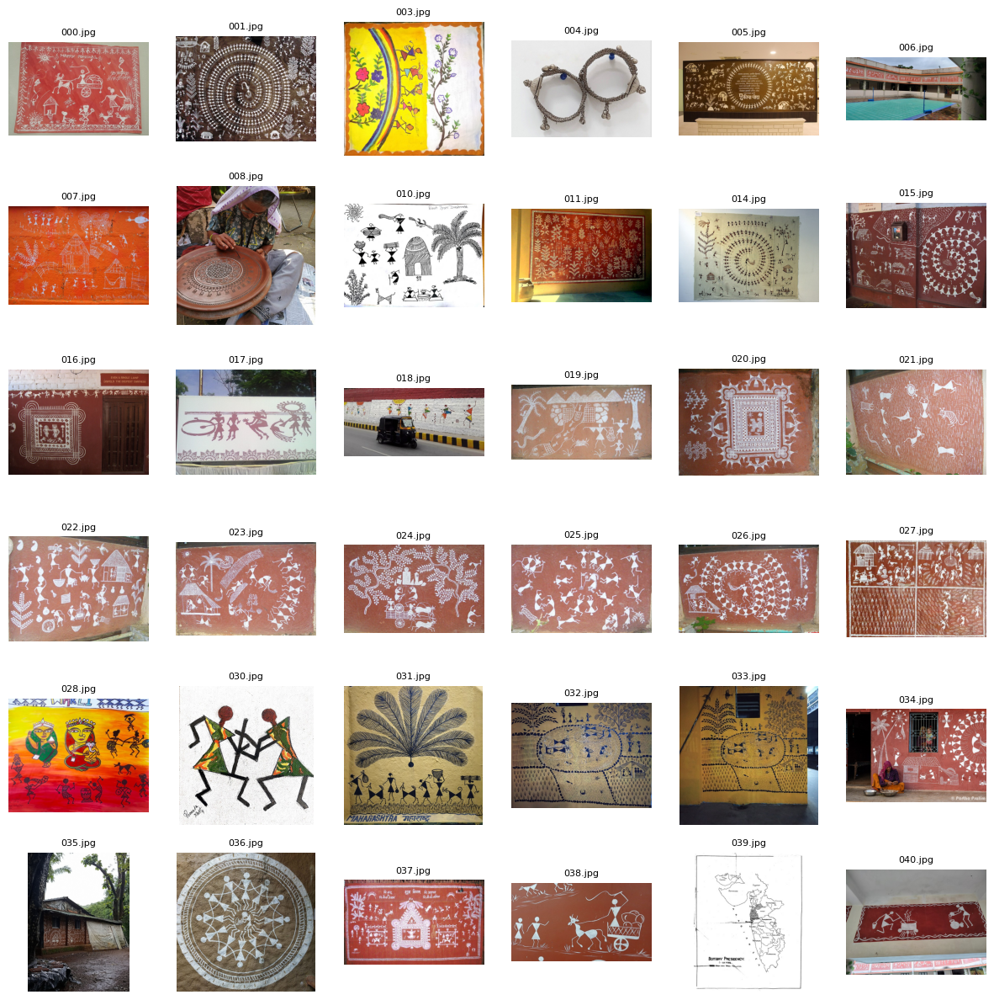

In [ ]:
import imagehash
import matplotlib.pyplot as plt

def auto_clean(folder, min_side=200):
    seen, kept = set(), 0
    for p in sorted(glob.glob(f"{folder}/*")):
        try:
            im = Image.open(p).convert("RGB")
            if min(im.size) < min_side:
                raise ValueError("too small")
            h = str(imagehash.phash(im))
            if h in seen:
                raise ValueError("duplicate")
            seen.add(h)
            im.thumbnail((800, 800))
            new = os.path.splitext(p)[0] + ".jpg"
            im.save(new, "JPEG", quality=90)
            if new != p:
                os.remove(p)
            kept += 1
        except Exception:
            if os.path.exists(p):
                os.remove(p)
    return kept

for a in ARTS:
    print(a, auto_clean(f"data/{a}"), "kept")

def show_grid(folder, cols=6, max_n=36):
    files = sorted(glob.glob(f"{folder}/*.jpg"))[:max_n]
    rows = (len(files) + cols - 1) // cols
    plt.figure(figsize=(cols * 2.5, rows * 2.5))
    for i, f in enumerate(files):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(Image.open(f)); plt.axis("off")
        plt.title(os.path.basename(f), fontsize=8)
    plt.show()

show_grid("data/warli")    # look for wrong images, e.g. photos of people, maps, logos

In [ ]:
to_delete = ["data/warli/003.jpg", "data/warli/004.jpg", "data/warli/005.jpg", "data/warli/006.jpg", "data/warli/008.jpg", "data/warli/016.jpg", "data/warli/018.jpg", "data/warli/028.jpg", "data/warli/034.jpg", "data/warli/035.jpg", "data/warli/039.jpg"]   # <- your list
for f in to_delete:
    if os.path.exists(f): os.remove(f)

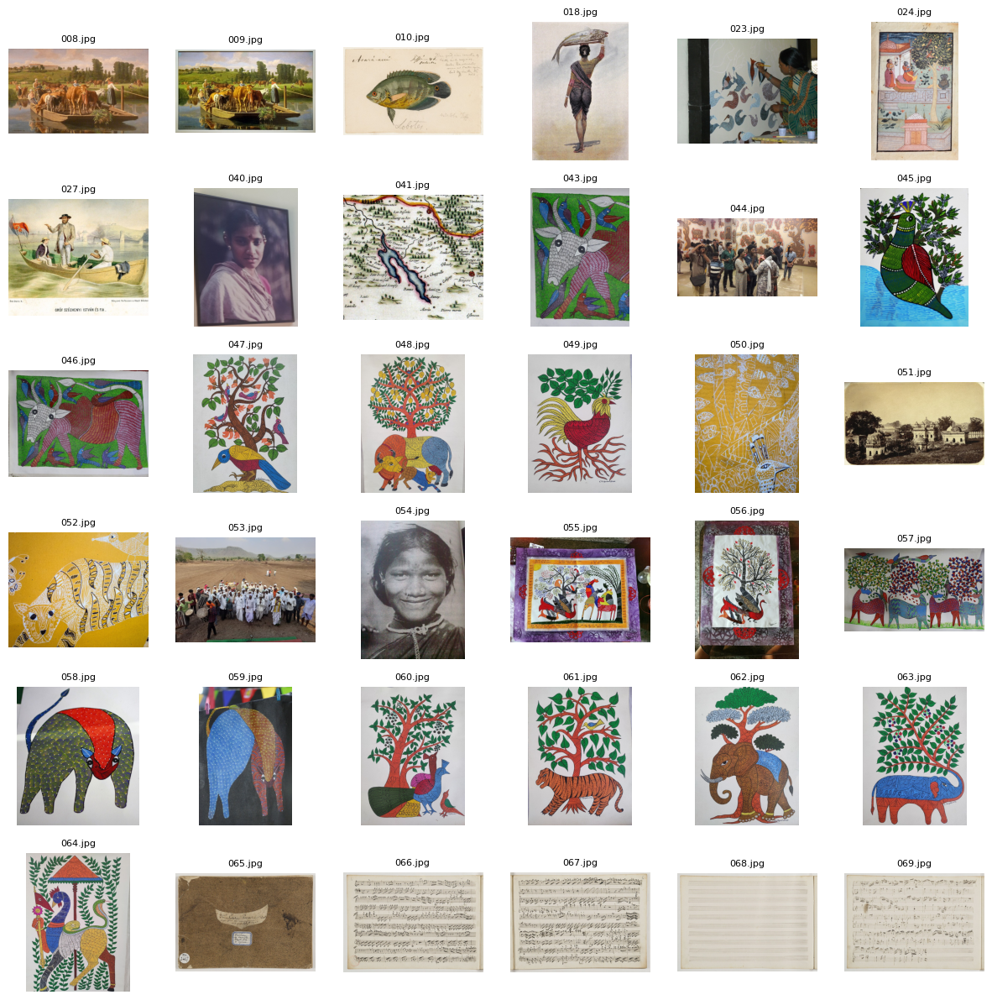

In [ ]:
show_grid("data/gond")

In [ ]:
to_delete = ["data/gond/023.jpg", "data/gond/040.jpg", "data/gond/044.jpg", "data/gond/051.jpg", "data/gond/053.jpg", "data/gond/054.jpg", "data/gond/065.jpg", "data/gond/066.jpg", "data/gond/067.jpg", "data/gond/068.jpg", "data/gond/069.jpg"]   # <- your list
for f in to_delete:
    if os.path.exists(f): os.remove(f)

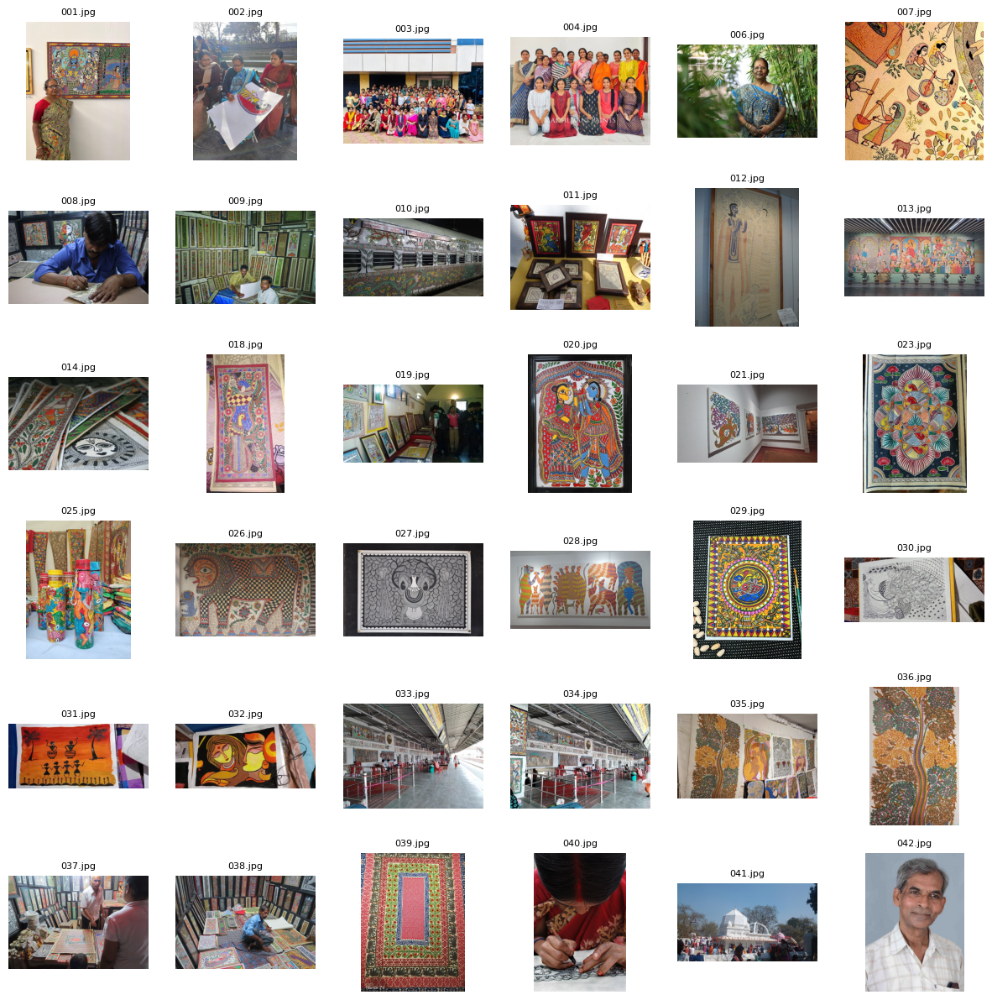

In [ ]:
show_grid("data/madhubani")

In [ ]:
to_delete = ["data/madhubani/001.jpg", "data/madhubani/002.jpg", "data/madhubani/003.jpg", "data/madhubani/004.jpg", "data/madhubani/006.jpg", "data/madhubani/008.jpg", "data/madhubani/009.jpg", "data/madhubani/010.jpg", "data/madhubani/033.jpg", "data/madhubani/034.jpg", "data/madhubani/037.jpg", "data/madhubani/038.jpg", "data/madhubani/040.jpg", "data/madhubani/041.jpg", "data/madhubani/042.jpg"]   # <- your list
for f in to_delete:
    if os.path.exists(f): os.remove(f)

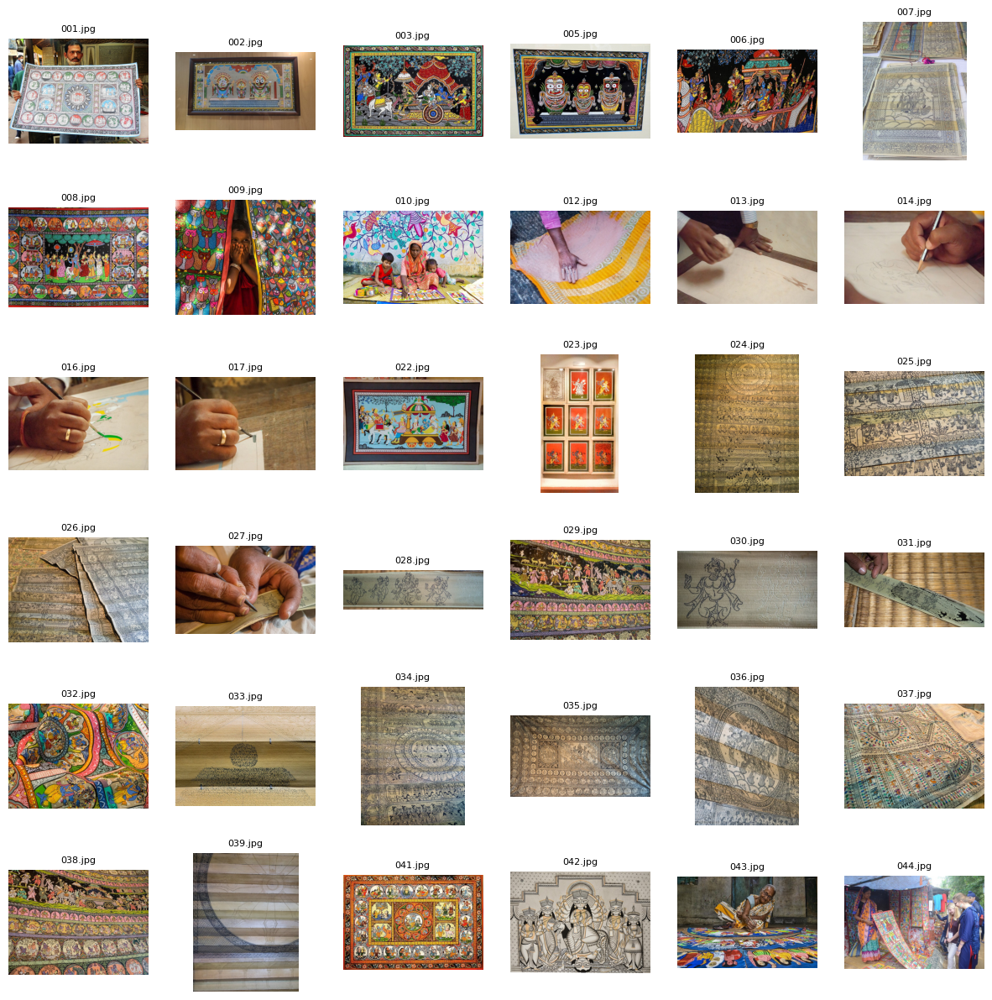

In [ ]:
show_grid("data/pattachitra")

In [ ]:
to_delete = ["data/pattachitra/001.jpg", "data/pattachitra/009.jpg", "data/pattachitra/010.jpg", "data/pattachitra/012.jpg", "data/pattachitra/013.jpg", "data/pattachitra/014.jpg", "data/pattachitra/016.jpg", "data/pattachitra/017.jpg", "data/pattachitra/027.jpg"]   # <- your list
for f in to_delete:
    if os.path.exists(f): os.remove(f)

In [ ]:
for a in ARTS:
    print(a, len(glob.glob(f"data/{a}/*.jpg")))

madhubani 30
warli 41
gond 33
pattachitra 28


In [ ]:
import torch
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_ID = "openai/clip-vit-base-patch32"
clip = CLIPModel.from_pretrained(MODEL_ID).to(device).eval()
proc = CLIPProcessor.from_pretrained(MODEL_ID)

@torch.no_grad()
def embed_pil_list(imgs):
    inp = proc(images=imgs, return_tensors="pt").to(device)
    f = clip.get_image_features(**inp)
    if not torch.is_tensor(f):          # some library versions return an object
        f = f.pooler_output
    f = f / f.norm(dim=-1, keepdim=True)
    return f.cpu().numpy()

def embed_paths(paths, bs=32):
    out = []
    for i in range(0, len(paths), bs):
        imgs = [Image.open(p).convert("RGB") for p in paths[i:i + bs]]
        out.append(embed_pil_list(imgs))
    return np.concatenate(out)

@torch.no_grad()
def embed_text(texts):
    inp = proc(text=texts, return_tensors="pt", padding=True, truncation=True).to(device)
    f = clip.get_text_features(**inp)
    if not torch.is_tensor(f):
        f = f.pooler_output
    f = f / f.norm(dim=-1, keepdim=True)
    return f.cpu().numpy()

# 1) Turn every image into an embedding
paths, labels = [], []
for a in ARTS:
    fs = sorted(glob.glob(f"data/{a}/*.jpg"))
    paths += fs; labels += [a] * len(fs)
X = embed_paths(paths)
y = np.array(labels)
print(X.shape)    # (num_images, 512)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

(132, 512)


              precision    recall  f1-score   support

        gond       0.70      1.00      0.82         7
   madhubani       0.50      0.50      0.50         6
 pattachitra       1.00      0.83      0.91         6
       warli       1.00      0.75      0.86         8

    accuracy                           0.78        27
   macro avg       0.80      0.77      0.77        27
weighted avg       0.81      0.78      0.78        27



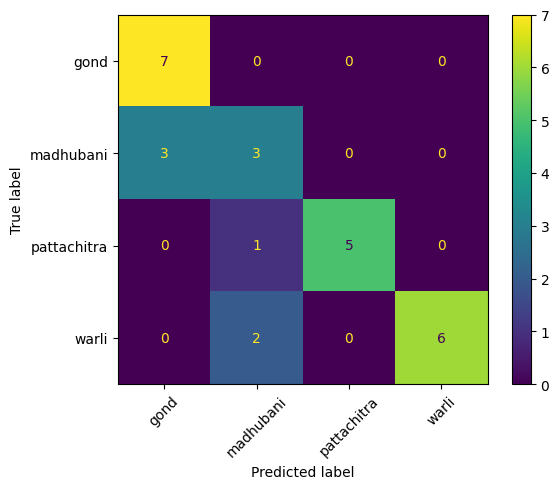

['clf.joblib']

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import joblib

Xtr, Xte, ytr, yte, ptr, pte = train_test_split(
    X, y, paths, test_size=0.2, stratify=y, random_state=42
)

clf = LogisticRegression(max_iter=3000, C=10, class_weight="balanced")
clf.fit(Xtr, ytr)

pred = clf.predict(Xte)
print(classification_report(yte, pred))
ConfusionMatrixDisplay.from_predictions(yte, pred, xticks_rotation=45)
plt.show()

joblib.dump(clf, "clf.joblib")

In [ ]:
kb = json.load(open("knowledge_base.json"))
classes = list(clf.classes_)
text_cache = {}
stats = {}

for art in ARTS:
    own = Xtr[ytr == art]
    other = Xtr[ytr != art]
    for f in kb[art]["features"]:
        t = embed_text([f["prompt"]])[0]
        text_cache[f"{art}/{f['id']}"] = t
        s_own, s_other = own @ t, other @ t
        std = float(s_own.std()) + 1e-6
        gap = float(s_own.mean() - s_other.mean())
        stats[f"{art}/{f['id']}"] = {
            "mean_own": float(s_own.mean()),
            "std_own": std,
            "mean_other": float(s_other.mean()),
            "reliable": bool(gap > 0.5 * std),    # feature must separate own vs other art
        }

json.dump(stats, open("feature_stats.json", "w"), indent=2)
np.save("text_feats.npy", text_cache, allow_pickle=True)

for k, v in stats.items():
    print(f"{k:35s} reliable={v['reliable']}")

madhubani/double_border             reliable=False
madhubani/fill_patterns             reliable=False
madhubani/no_empty_space            reliable=False
madhubani/motifs                    reliable=False
madhubani/faces_eyes                reliable=False
madhubani/flat_bold_color           reliable=False
warli/white_on_earth                reliable=True
warli/geometric_figures             reliable=True
warli/circle_dance                  reliable=True
warli/village_scenes                reliable=True
warli/geometric_frame               reliable=False
gond/dots_dashes                    reliable=False
gond/vivid_colors                   reliable=False
gond/tree_of_life                   reliable=False
gond/flowing_lines                  reliable=True
pattachitra/bold_outlines           reliable=False
pattachitra/big_eyes                reliable=True
pattachitra/floral_border           reliable=False
pattachitra/natural_palette         reliable=False
pattachitra/mythology               r

## Step 6b: Sanity-check the classifier (cross-validation)
Your test set is only 27 images, so one image changes accuracy by ~4%. 5-fold cross-validation uses all 132 images and gives a steadier number. It also lists which images get misclassified so you can fix the data (Madhubani had F1 = 0.50).

              precision    recall  f1-score   support

        gond       0.88      0.91      0.90        33
   madhubani       0.57      0.43      0.49        30
 pattachitra       0.81      0.89      0.85        28
       warli       0.82      0.88      0.85        41

    accuracy                           0.79       132
   macro avg       0.77      0.78      0.77       132
weighted avg       0.77      0.79      0.78       132



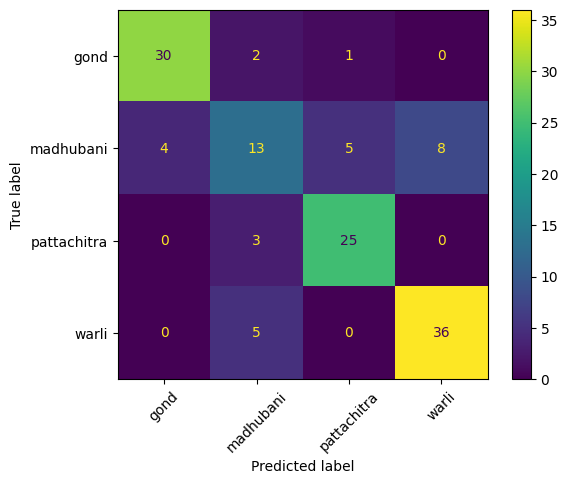

28 misclassified
data/madhubani/007.jpg              true=madhubani    predicted=pattachitra
data/madhubani/011.jpg              true=madhubani    predicted=pattachitra
data/madhubani/014.jpg              true=madhubani    predicted=pattachitra
data/madhubani/026.jpg              true=madhubani    predicted=pattachitra
data/madhubani/027.jpg              true=madhubani    predicted=gond
data/madhubani/028.jpg              true=madhubani    predicted=warli
data/madhubani/031.jpg              true=madhubani    predicted=warli
data/madhubani/036.jpg              true=madhubani    predicted=gond
data/madhubani/039.jpg              true=madhubani    predicted=pattachitra
data/madhubani/043.jpg              true=madhubani    predicted=warli
data/madhubani/044.jpg              true=madhubani    predicted=warli
data/madhubani/045.jpg              true=madhubani    predicted=warli
data/madhubani/046.jpg              true=madhubani    predicted=warli
data/madhubani/048.jpg              true=madh

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_pred = cross_val_predict(
    LogisticRegression(max_iter=3000, C=10, class_weight="balanced"), X, y, cv=cv)

print(classification_report(y, cv_pred))
ConfusionMatrixDisplay.from_predictions(y, cv_pred, xticks_rotation=45)
plt.show()

# Open these and check: wrong label? a photo of an artist? a mixed-style image? Delete or move them.
wrong = [(p, t, g) for p, t, g in zip(paths, y, cv_pred) if t != g]
print(len(wrong), "misclassified")
for p, t, g in wrong:
    print(f"{p:35s} true={t:12s} predicted={g}")

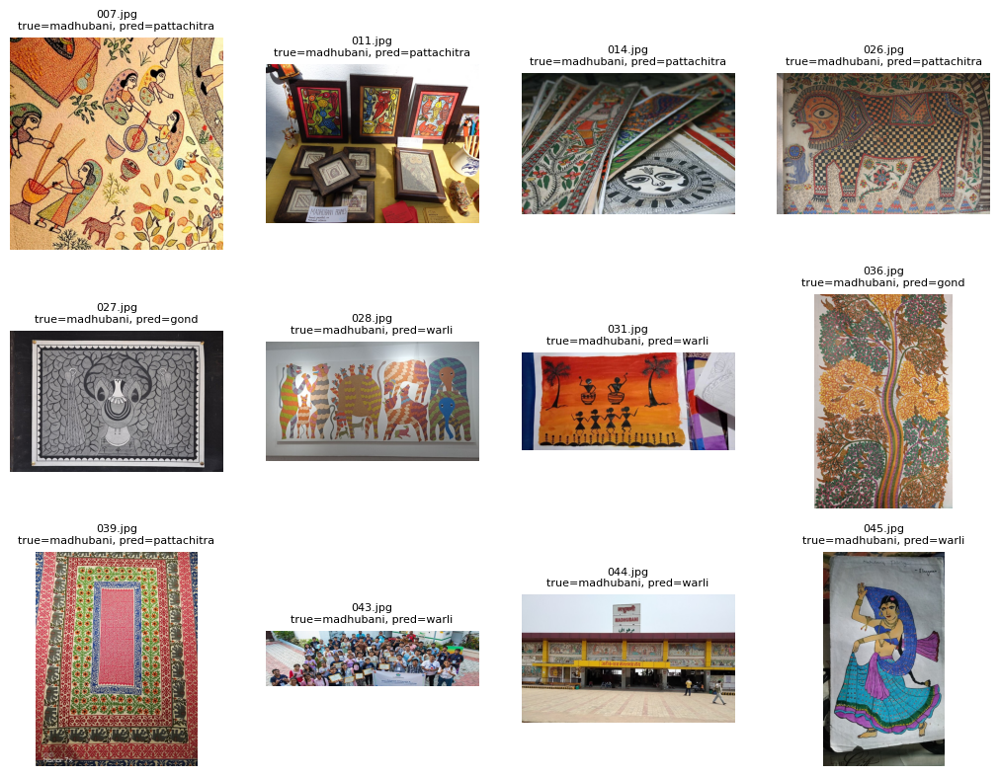

In [ ]:
# Look at the misclassified images (first 12)
bad = wrong[:12]
cols = 4
rows = max(1, (len(bad) + cols - 1) // cols)
plt.figure(figsize=(cols * 3.2, rows * 3.2))
for i, (p, t, g) in enumerate(bad):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(Image.open(p)); plt.axis("off")
    plt.title(f"{os.path.basename(p)}\ntrue={t}, pred={g}", fontsize=8)
plt.show()

**What to do with the result:** if an image above clearly isn't the art form in its folder, add its path to a delete list (like you did before), then re-run cells 12, 13 and 14. If you're short on time, skip this and continue.

## Step 6c: Final model on ALL images
For the demo, train on every image (not 80%) and recalibrate the feature statistics on all of them. More examples makes both the classifier and the feature z-scores more stable. The CV score above is your honest accuracy number for the pitch.

In [ ]:
clf = LogisticRegression(max_iter=3000, C=10, class_weight="balanced")
clf.fit(X, y)
joblib.dump(clf, "clf.joblib")

kb = json.load(open("knowledge_base.json"))
text_cache, stats = {}, {}
for art in ARTS:
    own = X[y == art]
    other = X[y != art]
    for f in kb[art]["features"]:
        t = embed_text([f["prompt"]])[0]
        key = f"{art}/{f['id']}"
        text_cache[key] = t
        s_own, s_other = own @ t, other @ t
        std = float(s_own.std()) + 1e-6
        gap = float(s_own.mean() - s_other.mean())
        stats[key] = {
            "mean_own": float(s_own.mean()),
            "std_own": std,
            "mean_other": float(s_other.mean()),
            "gap_in_std": round(gap / std, 2),
            "reliable": bool(gap > 0.5 * std),
        }

json.dump(stats, open("feature_stats.json", "w"), indent=2)
np.save("text_feats.npy", text_cache, allow_pickle=True)

n_rel = sum(v["reliable"] for v in stats.values())
print(f"{n_rel}/{len(stats)} features reliable")
for k, v in stats.items():
    print(f"{k:35s} reliable={v['reliable']}  gap={v['gap_in_std']:+.2f} std")

4/20 features reliable
madhubani/double_border             reliable=False  gap=-0.21 std
madhubani/fill_patterns             reliable=False  gap=-0.21 std
madhubani/no_empty_space            reliable=False  gap=-0.23 std
madhubani/motifs                    reliable=False  gap=-0.15 std
madhubani/faces_eyes                reliable=False  gap=-0.21 std
madhubani/flat_bold_color           reliable=False  gap=+0.36 std
warli/white_on_earth                reliable=True  gap=+0.79 std
warli/geometric_figures             reliable=True  gap=+1.01 std
warli/circle_dance                  reliable=True  gap=+0.60 std
warli/village_scenes                reliable=False  gap=+0.45 std
warli/geometric_frame               reliable=False  gap=-0.13 std
gond/dots_dashes                    reliable=False  gap=+0.34 std
gond/vivid_colors                   reliable=False  gap=+0.39 std
gond/tree_of_life                   reliable=False  gap=+0.22 std
gond/flowing_lines                  reliable=False  gap=

Features marked `reliable=False` are reported as "unsure" by the checker, and the Gemini coach judges them by looking at the image directly, so nothing is lost. If you want more reliable features, rewrite the `prompt` in `knowledge_base` to describe what the eye literally sees (colors, shapes, layout), then re-run Step 6c.

## Step 7: The analyzer (classifier + feature checks)

In [ ]:
def analyze(pil_img, target):
    x = embed_pil_list([pil_img.convert("RGB")])[0]

    # A. Style match
    probs = clf.predict_proba([x])[0]
    prob_dict = {c: float(p) for c, p in zip(clf.classes_, probs)}
    match = prob_dict[target]
    top = max(prob_dict, key=prob_dict.get)

    # B. Feature check (z-score vs genuine examples of the target style)
    report = []
    for f in kb[target]["features"]:
        key = f"{target}/{f['id']}"
        st = stats[key]
        s = float(x @ text_cache[key])
        z = (s - st["mean_own"]) / st["std_own"]
        if not st["reliable"]:
            status = "unsure"
        elif z > -0.5:
            status = "present"
        elif z > -1.5:
            status = "weak"
        else:
            status = "missing"
        report.append({"feature": f["id"], "status": status, "z": round(z, 2),
                       "tip": f["tip"], "description": f["description"]})
    return {"target": target, "match": match, "top_guess": top,
            "probs": prob_dict, "features": report}

# Smoke test (note: these images were used for training, so scores will look optimistic)
img = Image.open(pte[0])
res = analyze(img, yte[0])
print("true:", yte[0], "| match:", round(res["match"], 2), "| top guess:", res["top_guess"])
for r in res["features"]:
    print(f"  {r['feature']:20s} {r['status']:8s} z={r['z']}")

true: madhubani | match: 0.67 | top guess: madhubani
  double_border        unsure   z=1.06
  fill_patterns        unsure   z=1.02
  no_empty_space       unsure   z=0.93
  motifs               unsure   z=0.81
  faces_eyes           unsure   z=-0.21
  flat_bold_color      unsure   z=0.54


## Step 8: The coach writer (Gemini + your knowledge base)

1. In Colab, open the key icon (**Secrets**) in the left sidebar.
2. Add a secret named `GEMINI_API_KEY` (get one free at aistudio.google.com/apikey) and turn on **Notebook access**.

The classifier and feature signals keep Gemini grounded in your art-form facts; Gemini looks at the actual picture and writes the advice.

In [ ]:
from google import genai
from google.genai import types
from google.colab import userdata

gclient = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
GEMINI_MODEL = "gemini-3.8-flash-lite"      # if you get a "model not found" error, change this name

def pil_to_jpeg_bytes(img, max_side=1024):
    img = img.convert("RGB")
    img.thumbnail((max_side, max_side))
    buf = io.BytesIO()
    img.save(buf, "JPEG", quality=85)
    return buf.getvalue()

def coach(pil_img, target, analysis, lang="English"):
    art = kb[target]
    status = {r["feature"]: r["status"] for r in analysis["features"]}
    feat_lines = "\n".join(
        f"- {f['id']}: {f['description']} (automated check: {status[f['id']]})"
        for f in art["features"]
    )
    system = f"""You are a kind, knowledgeable teacher of {art['name']} ({art['origin']}).
A beginner uploaded their painting while attempting this art form. Give honest, encouraging, specific feedback.

Key features of this art form:
{feat_lines}

Automated signals (rough, may be wrong; verify against the image yourself):
- Style match score for {target}: {analysis['match']:.0%}
- The classifier thinks it looks most like: {analysis['top_guess']}

Rules:
- Judge only what is visible in the image. Do not invent details.
- Refer to specific places in the painting (e.g. "the border at the top", "the figure on the left").
- Be culturally respectful. Mention the meaning or tradition behind a feature when it helps the learner.
- If the image is not a painting or drawing (a selfie, food, a screenshot), set "is_artwork" to false and explain kindly in "overall".
- If it looks more like a different folk art form, say which one in "style_match_comment".
Respond ONLY with valid JSON in exactly this shape:
{{"is_artwork": true,
 "overall": "<2 sentence encouraging summary>",
 "style_match_comment": "<how close it is to {target} and why>",
 "strengths": ["<up to 3>"],
 "mistakes": [{{"issue": "<what's wrong or missing>", "why_it_matters": "<tradition/reason>", "fix": "<specific steps to fix>"}}],
 "next_exercise": "<one small practice task>"}}
Write all text values in {lang}."""

    last_err = None
    for attempt in range(3):
        try:
            resp = gclient.models.generate_content(
                model=GEMINI_MODEL,
                contents=[
                    types.Part.from_bytes(data=pil_to_jpeg_bytes(pil_img), mime_type="image/jpeg"),
                    f"Please review my attempt at {art['name']}.",
                ],
                config=types.GenerateContentConfig(
                    system_instruction=system,
                    response_mime_type="application/json",
                    temperature=0.4,
                ),
            )
            text = resp.text.replace("```json", "").replace("```", "").strip()
            out = json.loads(text)
            out.setdefault("is_artwork", True)
            out.setdefault("strengths", [])
            out.setdefault("mistakes", [])
            out.setdefault("next_exercise", "")
            out.setdefault("style_match_comment", "")
            return out
        except Exception as e:
            last_err = e
            time.sleep(2)
    raise RuntimeError(f"Coach failed after 3 tries: {last_err}")

# Test
a = analyze(img, yte[0])
print(json.dumps(coach(img, yte[0], a), indent=2, ensure_ascii=False))

RuntimeError: Coach failed after 3 tries: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'models/gemini-3.8-flash-lite is not found for API version v1beta, or is not supported for generateContent. Call ModelService.ListModels to see the list of available models and their supported methods.', 'status': 'NOT_FOUND'}}

In [ ]:
# 1) Models your key can actually use
models = [m.name.replace("models/", "") for m in gclient.models.list()
          if "generateContent" in (m.supported_actions or [])]
BAD = ("image", "tts", "audio", "live", "embed", "robotics", "computer")
candidates = [m for m in models if "flash" in m and not any(b in m for b in BAD)]
print("Will try:", candidates)

# 2) Auto-fallback: wrong model (404) -> next model; busy (503) -> wait and retry
_orig = gclient.models.generate_content
def _generate(model=None, **kw):
    err = None
    for m in candidates:
        for wait in (0, 5, 15):
            time.sleep(wait)
            try:
                return _orig(model=m, **kw)
            except Exception as e:
                err = e
                if "404" in str(e):
                    break
    raise err
gclient.models.generate_content = _generate

# 3) Re-run the test
a = analyze(img, yte[0])
print(json.dumps(coach(img, yte[0], a), indent=2, ensure_ascii=False))

Will try: ['gemini-2.5-flash', 'gemini-flash-latest', 'gemini-flash-lite-latest', 'gemini-2.5-flash-lite', 'gemini-3-flash-preview', 'gemini-3.1-flash-lite-preview', 'gemini-3.1-flash-lite', 'gemini-3.5-flash', 'gemini-3.5-flash-lite', 'gemini-omni-flash-preview', 'gemini-omni-1.1-flash', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash']
{
  "is_artwork": true,
  "overall": "This is a magnificent, richly detailed painting full of rhythm, balance, and lively animal forms. However, the stylistic techniques and textures used here belong directly to Gond tribal art rather than the Madhubani / Mithila tradition.",
  "style_match_comment": "While this is an exquisite piece of Indian folk art, it is distinctly Gond painting from central India rather than Madhubani. Gond art is defined by fluid animal silhouettes filled with repeating curved strokes, scales, and dashes against open space, whereas Madhubani is characterized by double outlines, fine linear hatching (kachni), solid colo

## Step 9: Test properly before the demo
Run these checks (cells below). Upload your own test images in the Colab Files sidebar and change the paths.

In [ ]:
# Wrong-style test: take a Warli test image but pretend the learner was attempting Madhubani.
# Expect: low style match, top guess = warli, coach says it looks more like Warli.
warli_idx = [i for i, t in enumerate(yte) if t == "warli"][0]
w_img = Image.open(pte[warli_idx])
a = analyze(w_img, "madhubani")
print(f"Style match for madhubani: {a['match']:.0%} | top guess: {a['top_guess']}")
c = coach(w_img, "madhubani", a)
print(c["style_match_comment"])

Style match for madhubani: 4% | top guess: warli
This painting is almost entirely Warli art from Maharashtra, characterized by white geometric stick figures made of paired triangles on a red-ochre background, rather than Madhubani art from Bihar.


In [ ]:
# Junk test: any non-painting photo. Upload one (e.g. junk.jpg) via the Files sidebar first.
JUNK_PATH = "junk.jpg"      # <- change to your file
if os.path.exists(JUNK_PATH):
    j = Image.open(JUNK_PATH)
    c = coach(j, "warli", analyze(j, "warli"))
    print("is_artwork:", c["is_artwork"])
    print(c["overall"])
else:
    print("Upload a non-painting photo as", JUNK_PATH, "to run this test")

Upload a non-painting photo as junk.jpg to run this test


## Save everything to Drive (run BEFORE launching the demo, since the demo cell keeps running)

In [ ]:
import shutil
for f in ["clf.joblib", "feature_stats.json", "text_feats.npy", "knowledge_base.json", "image_credits.csv"]:
    if os.path.exists(f):
        shutil.copy(f, "/content/drive/MyDrive/folkart/")
print(os.listdir("/content/drive/MyDrive/folkart"))

['clf.joblib', 'feature_stats.json', 'text_feats.npy', 'knowledge_base.json', 'image_credits.csv']


## Export the model bundle for the Parampara Proof website
Run this after Step 6c. It creates `parampara_model.zip` containing everything the backend (`app.py`) needs, saves a copy to Drive and downloads it to your computer.

In [ ]:
import shutil, sklearn

# JSON instead of pickle for the text vectors: safer and loads anywhere
json.dump({k: v.tolist() for k, v in text_cache.items()}, open("text_feats.json", "w"))
json.dump({"clip_model": MODEL_ID, "classes": list(clf.classes_), "arts": ARTS,
           "sklearn_version": sklearn.__version__}, open("model_meta.json", "w"), indent=2)

BUNDLE = "parampara_model"
shutil.rmtree(BUNDLE, ignore_errors=True)
os.makedirs(BUNDLE)
for f in ["clf.joblib", "feature_stats.json", "text_feats.json", "knowledge_base.json",
          "model_meta.json", "image_credits.csv"]:
    shutil.copy(f, BUNDLE)

shutil.make_archive(BUNDLE, "zip", BUNDLE)
shutil.copy(BUNDLE + ".zip", "/content/drive/MyDrive/folkart/")
print("sklearn version to pin in requirements.txt:", sklearn.__version__)
print(os.listdir(BUNDLE))

from google.colab import files
files.download(BUNDLE + ".zip")

sklearn version to pin in requirements.txt: 1.6.1
['text_feats.json', 'clf.joblib', 'image_credits.csv', 'feature_stats.json', 'knowledge_base.json', 'model_meta.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 10: Gradio demo
Prints a public `https://xxxx.gradio.live` link you can open on your phone. It stays alive for as long as this cell is running (and the Colab runtime is connected).

In [ ]:
import gradio as gr

def typical_examples(art, k=3):
    idx = np.where(y == art)[0]
    centroid = X[idx].mean(axis=0)
    centroid /= np.linalg.norm(centroid)
    best = idx[np.argsort(-(X[idx] @ centroid))[:k]]
    return [paths[i] for i in best]

ICON = {"present": "✅", "weak": "⚠️", "missing": "❌", "unsure": "❔"}

def run(pil_img, target, language):
    if pil_img is None:
        return {}, "Please upload a painting.", ""
    a = analyze(pil_img, target)
    try:
        c = coach(pil_img, target, a, lang=language)
    except Exception as e:
        return a["probs"], "", f"Coach error: {e}"

    checks = "\n\n".join(
        f"{ICON[r['status']]} **{r['feature'].replace('_', ' ').title()}**: {r['status']}"
        for r in a["features"]
    )
    if not c["is_artwork"]:
        return a["probs"], checks, f"### {c['overall']}"

    mistakes = "\n\n".join(
        f"**{i+1}. {m.get('issue','')}**\n- Why it matters: {m.get('why_it_matters','')}\n- How to fix: {m.get('fix','')}"
        for i, m in enumerate(c["mistakes"])
    )
    text = (
        f"### {c['overall']}\n\n**Style match ({target}): {a['match']:.0%}**: {c['style_match_comment']}\n\n"
        "**Strengths**\n" + "\n".join(f"- {s}" for s in c["strengths"]) +
        f"\n\n**What to improve**\n\n{mistakes}\n\n**Next exercise:** {c['next_exercise']}"
    )
    return a["probs"], checks, text

def teach(target):
    art = kb[target]
    md_ = f"## {art['name']}\n*{art['origin']}*\n\n"
    for f in art["features"]:
        md_ += f"**{f['id'].replace('_', ' ').title()}**: {f['description']}\n\n"
    return md_, typical_examples(target)

with gr.Blocks() as demo:
    gr.Markdown("# 🎨 Folk Art AI Coach")
    with gr.Tab("Learn the style"):
        dd = gr.Dropdown(ARTS, value="warli", label="Art form")
        out_md = gr.Markdown()
        gal = gr.Gallery(label="Typical examples (see image_credits.csv for sources)", columns=3, height=260)
        dd.change(teach, dd, [out_md, gal])
        demo.load(teach, dd, [out_md, gal])
    with gr.Tab("Check my painting"):
        with gr.Row():
            with gr.Column():
                inp = gr.Image(type="pil", label="Upload your painting")
                tgt = gr.Dropdown(ARTS, value="warli", label="Which art form were you attempting?")
                lng = gr.Dropdown(["English", "Hindi", "Bengali"], value="English", label="Language")
                btn = gr.Button("Check my work", variant="primary")
            with gr.Column():
                lab = gr.Label(label="Which style does it look like?")
                chk = gr.Markdown()
                fb = gr.Markdown()
        btn.click(run, [inp, tgt, lng], [lab, chk, fb])

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://177b5876e81e73303e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://177b5876e81e73303e.gradio.live
